<a href="https://colab.research.google.com/github/fadlifernando10/pm-turi4-clustering/blob/main/PM_TURI_4_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah awal — Membuat dataset segmentasi pelanggan (buatan)


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

rng = np.random.default_rng(42)

def buat_segmen(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia':         rng.normal(usia[0], usia[1], n),
        'pendapatan':   rng.normal(pendapatan[0], pendapatan[1], n),
        'skor_belanja': rng.normal(skor[0], skor[1], n),
    })

df = pd.concat([
    buat_segmen(100, (25, 4), (7e6, 1.5e6),  (80, 8)),   # muda, pendapatan sedang, belanja tinggi
    buat_segmen(100, (45, 5), (20e6, 3e6),   (55, 10)),  # paruh baya, pendapatan tinggi, belanja sedang
    buat_segmen(100, (58, 5), (5e6, 1.2e6),  (25, 8)),   # senior, pendapatan rendah, belanja rendah
], ignore_index=True)

df['usia'] = df['usia'].clip(18, 70).round().astype(int)
df['pendapatan'] = (df['pendapatan'].clip(2e6) / 1e5).round() * 1e5
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round().astype(int)

print(df.shape)
df.head()

(300, 3)


,usia,pendapatan,skor_belanja
0,26,6400000.0,83
1,21,8900000.0,91
2,28,6500000.0,81
3,29,8100000.0,85
4,18,5600000.0,64


In [2]:
print(df.isna().sum().to_string(), '\n')
df.describe().round(1)

usia            0
pendapatan      0
skor_belanja    0 



,usia,pendapatan,skor_belanja
count,300.0,300.0,300.0
mean,42.6,10634666.7,52.4
std,14.2,6893819.5,24.5
min,18.0,2300000.0,4.0
25%,27.0,5500000.0,27.8
50%,46.0,7050000.0,54.0
75%,54.2,18000000.0,75.0
max,70.0,27800000.0,100.0


Perhatikan rentang tiap fitur: `usia` berkisar 18–70 dan `skor_belanja` 1–100, sedangkan `pendapatan` berkisar jutaan hingga puluhan juta rupiah. Perbedaan skala inilah yang akan mendominasi jarak Euclidean jika tidak di-scaling.

## Langkah 1 — Menyiapkan data & scaling (wajib)

In [3]:
from sklearn.preprocessing import StandardScaler

# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

print('Rata-rata setelah scaling :', X_scaled.mean(axis=0).round(3))
print('Std setelah scaling       :', X_scaled.std(axis=0).round(3))

Rata-rata setelah scaling : [ 0.  0. -0.]
Std setelah scaling       : [1. 1. 1.]


Setelah `StandardScaler`, tiap fitur memiliki rata-rata ≈ 0 dan standar deviasi = 1, sehingga ketiganya berkontribusi **setara** pada perhitungan jarak.

## Langkah 2 — Metode Elbow menentukan K

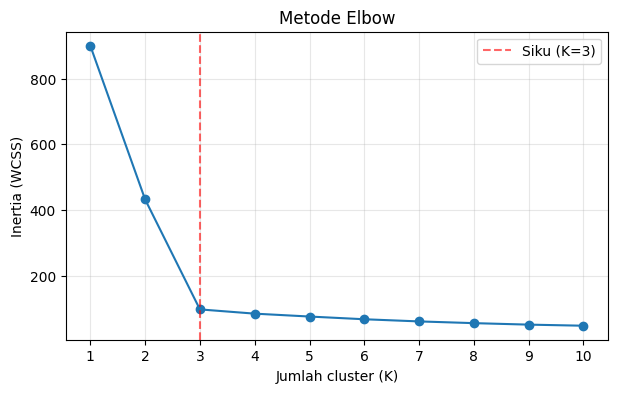

,Inertia,Penurunan
K,,
1,900.0,NaN
2,431.8,468.2
3,96.7,335.1
4,83.8,12.9
5,75.0,8.8
6,66.7,8.3
7,60.1,6.6
8,54.9,5.3
9,50.3,4.5


In [4]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1,11), inertias, marker='o')
plt.axvline(3, color='red', ls='--', alpha=.6, label='Siku (K=3)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia (WCSS)')
plt.title('Metode Elbow'); plt.xticks(range(1,11)); plt.legend(); plt.grid(alpha=.3)
plt.show()

pd.DataFrame({'K': range(1,11), 'Inertia': np.round(inertias,1),
              'Penurunan': [np.nan]+list(np.round(-np.diff(inertias),1))}).set_index('K')

**Hasil:** inertia turun sangat tajam dari K=1 (900,0) → K=2 (431,8) → K=3 (96,7), lalu setelah K=3 penurunannya hanya sekitar 13 poin atau kurang per tambahan cluster (kurva melandai). Jadi **siku berada di K = 3**, dan inilah K yang kita pakai.

## Langkah 3 — Menjalankan K-Means (K=3)

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(df['cluster'].value_counts().sort_index())
print('\nInertia :', round(kmeans.inertia_, 2))
print('Centroid (skala terstandar):'); print(kmeans.cluster_centers_.round(2))

cluster
0    100
1    100
2    100
Name: count, dtype: int64

Inertia : 96.71
Centroid (skala terstandar):
[[ 0.21  1.34  0.07]
 [ 1.04 -0.81 -1.17]
 [-1.25 -0.53  1.11]]


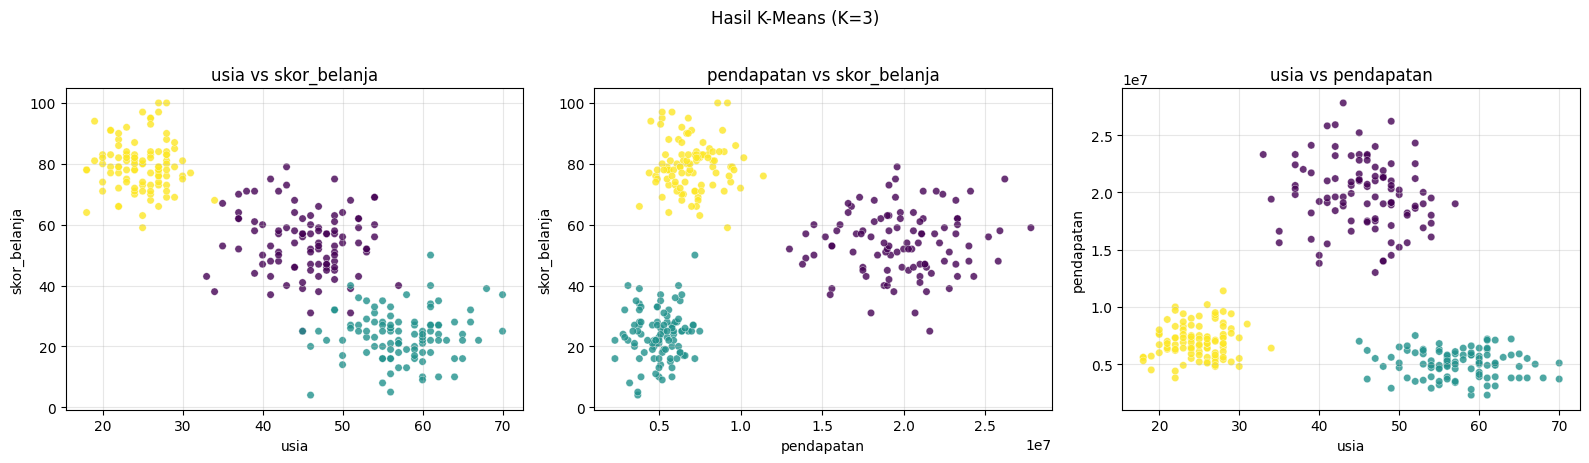

In [6]:
# Visualisasi hasil: tiga proyeksi 2D dari tiga fitur
pasangan = [('usia','skor_belanja'), ('pendapatan','skor_belanja'), ('usia','pendapatan')]
fig, ax = plt.subplots(1, 3, figsize=(16,4.5))
for a,(fx,fy) in zip(ax,pasangan):
    sc = a.scatter(df[fx], df[fy], c=df['cluster'], cmap='viridis', s=28, alpha=.8, edgecolor='white', linewidth=.3)
    a.set_xlabel(fx); a.set_ylabel(fy); a.set_title(f'{fx} vs {fy}'); a.grid(alpha=.3)
plt.suptitle('Hasil K-Means (K=3)', y=1.02); plt.tight_layout(); plt.show()

## Langkah 4 — Evaluasi silhouette score

In [11]:
from sklearn.metrics import silhouette_score

sil_k3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette score (K=3, scaled):', round(sil_k3, 4))

Silhouette score (K=3, scaled): 0.7177


**Interpretasi:** silhouette ≈ **0,72**. Nilai ini jauh di atas 0 dan mendekati +1, artinya sebagian besar titik berada jauh di dalam clusternya sendiri dan terpisah jelas dari cluster tetangga. Struktur tiga kelompok pada data ini kuat.

## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [8]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
print(profil) # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja  jumlah
cluster                                        
0        45.5  19867000.0          54.0     100
1        57.4   5049000.0          23.7     100
2        24.8   6988000.0          79.5     100


In [9]:
# Penamaan cluster berdasarkan profil (aturan sederhana agar tidak bergantung pada nomor cluster)
nama = {}
nama[profil['usia'].idxmin()]       = 'Muda Hobi Belanja'
nama[profil['pendapatan'].idxmax()] = 'Mapan Selektif'
nama[profil['usia'].idxmax()]       = 'Senior Hemat'
df['segmen'] = df['cluster'].map(nama)

profil_nama = profil.rename(index=nama)
profil_nama['pendapatan'] = (profil_nama['pendapatan']/1e6).round(1)
profil_nama = profil_nama.rename(columns={'pendapatan':'pendapatan (juta Rp/bln)'})
profil_nama

,usia,pendapatan (juta Rp/bln),skor_belanja,jumlah
cluster,,,,
Mapan Selektif,45.5,19.9,54.0,100
Senior Hemat,57.4,5.0,23.7,100
Muda Hobi Belanja,24.8,7.0,79.5,100


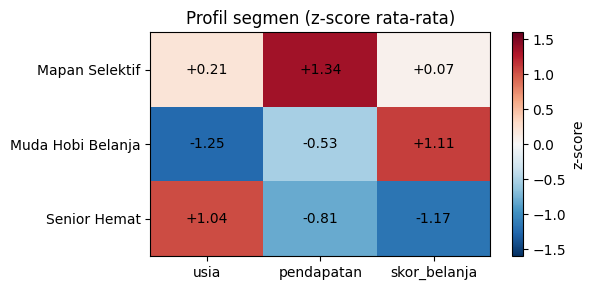

In [10]:
# Visual profil: rata-rata terstandar tiap segmen (heatmap sederhana)
z = pd.DataFrame(X_scaled, columns=['usia','pendapatan','skor_belanja']).groupby(df['segmen']).mean()
fig, ax = plt.subplots(figsize=(6,3))
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-1.6, vmax=1.6, aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels(z.columns); ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]): ax.text(j,i,f'{z.values[i,j]:+.2f}',ha='center',va='center')
plt.colorbar(im, label='z-score'); ax.set_title('Profil segmen (z-score rata-rata)'); plt.tight_layout(); plt.show()

### Penamaan & interpretasi cluster

| Segmen | Usia | Pendapatan | Skor belanja | Makna bagi pemasaran |
|---|---|---|---|---|
| **Muda Hobi Belanja** | ≈ 25 th | ≈ Rp 7 jt/bln (menengah-bawah) | ≈ 80 (tinggi) | Pelanggan paling aktif meski pendapatan sedang. Cocok untuk promo, cicilan, program loyalitas, dan kampanye media sosial. |
| **Mapan Selektif** | ≈ 45 th | ≈ Rp 20 jt/bln (tinggi) | ≈ 54 (sedang) | Daya beli besar tetapi belanja belum maksimal. Peluang untuk produk premium dan penawaran personal. |
| **Senior Hemat** | ≈ 57 th | ≈ Rp 5 jt/bln (rendah) | ≈ 24 (rendah) | Belanja paling rendah dan sensitif harga. Cocok untuk diskon kebutuhan pokok dan promo hemat. |

Ketiga segmen berukuran seimbang (masing-masing 100 pelanggan) dan masing-masing punya profil yang jelas berbeda, sehingga tiap segmen dapat diberi strategi pemasaran sendiri.

---
## D. Latihan Mandiri

### Latihan 6 — K-Means dengan K=5, bandingkan silhouette score dengan K=3

,Silhouette,Inertia
K,,
3,0.7177,96.7
5,0.5775,75.0


Ukuran cluster K=5: [100  37 100  28  35]


cluster (K=5),0,1,2,3,4
segmen (K=3),,,,,
Mapan Selektif,0,37,0,28,35
Muda Hobi Belanja,100,0,0,0,0
Senior Hemat,0,0,100,0,0


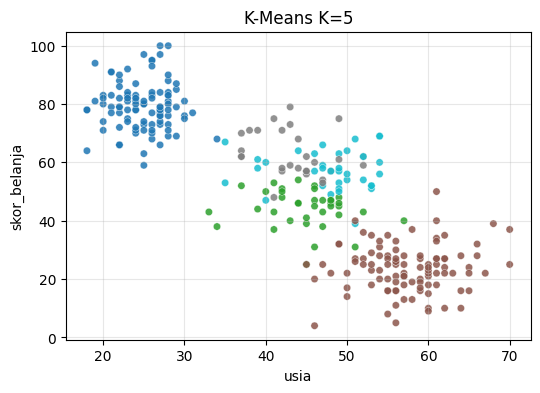

In [12]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_k5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, label_k5)

hasil6 = pd.DataFrame({'K':[3,5], 'Silhouette':[round(sil_k3,4), round(sil_k5,4)],
                       'Inertia':[round(kmeans.inertia_,1), round(km5.inertia_,1)]}).set_index('K')
display(hasil6)
print('Ukuran cluster K=5:', np.bincount(label_k5))
display(pd.crosstab(df['segmen'], label_k5, rownames=['segmen (K=3)'], colnames=['cluster (K=5)']))

plt.figure(figsize=(6,4))
plt.scatter(df['usia'], df['skor_belanja'], c=label_k5, cmap='tab10', s=28, alpha=.85, edgecolor='white', linewidth=.3)
plt.xlabel('usia'); plt.ylabel('skor_belanja'); plt.title('K-Means K=5'); plt.grid(alpha=.3); plt.show()

**Kesimpulan Latihan 6:** silhouette K=3 (**0,718**) lebih tinggi daripada K=5 (**0,577**). Walaupun inertia K=5 lebih kecil (itu pasti terjadi karena cluster lebih banyak), kualitas pemisahannya justru turun. Tabel silang di atas menunjukkan K=5 hanya memecah kelompok **Mapan Selektif** menjadi tiga sub-kelompok (37, 28, 35 orang) yang saling bersinggungan, sedangkan **Muda Hobi Belanja** dan **Senior Hemat** tetap utuh (masing-masing 100). Pemecahan itu tidak mencerminkan perbedaan nyata di data, sehingga pemisahan antar-cluster memburuk. Ini mendukung hasil Elbow bahwa **K=3 adalah pilihan terbaik**.

### Latihan 7 — K-Means tanpa scaling (K=3), bandingkan silhouette-nya

In [14]:
km_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
label_raw = km_raw.fit_predict(df[['usia','pendapatan','skor_belanja']].values)

sil_raw_raw    = silhouette_score(df[['usia','pendapatan','skor_belanja']].values, label_raw)  # diukur di skala asli
sil_raw_scaled = silhouette_score(X_scaled, label_raw)                                         # diukur di skala adil
print('Silhouette tanpa scaling (diukur skala asli)     :', round(sil_raw_raw, 4))
print('Silhouette tanpa scaling (diukur skala terstandar):', round(sil_raw_scaled, 4))
print('Silhouette dengan scaling                         :', round(sil_k3, 4))

print('\nUkuran cluster tanpa scaling :', np.bincount(label_raw))
print('Ukuran cluster dengan scaling:', np.bincount(df['cluster']))

# Seberapa cocok pembagian tanpa scaling dengan kelompok asli?
print('\nTabel silang cluster tanpa scaling vs segmen:')
display(pd.crosstab(df['segmen'], label_raw, rownames=['segmen (scaled)'], colnames=['cluster (tanpa scaling)']))

Silhouette tanpa scaling (diukur skala asli)     : 0.7345
Silhouette tanpa scaling (diukur skala terstandar): 0.2084
Silhouette dengan scaling                         : 0.7177

Ukuran cluster tanpa scaling : [200  53  47]
Ukuran cluster dengan scaling: [100 100 100]

Tabel silang cluster tanpa scaling vs segmen:


cluster (tanpa scaling),0,1,2
segmen (scaled),,,
Mapan Selektif,0,53,47
Muda Hobi Belanja,100,0,0
Senior Hemat,100,0,0


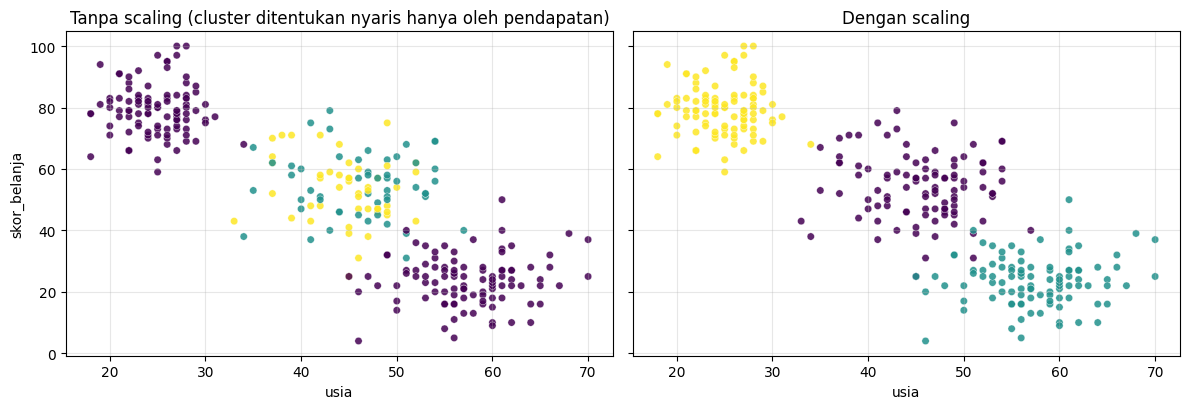

In [15]:
fig, ax = plt.subplots(1,2, figsize=(12,4.2), sharey=True)
ax[0].scatter(df['usia'], df['skor_belanja'], c=label_raw,      cmap='viridis', s=28, alpha=.85, edgecolor='white', linewidth=.3)
ax[0].set_title('Tanpa scaling (cluster ditentukan nyaris hanya oleh pendapatan)')
ax[1].scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=28, alpha=.85, edgecolor='white', linewidth=.3)
ax[1].set_title('Dengan scaling')
for a in ax: a.set_xlabel('usia'); a.grid(alpha=.3)
ax[0].set_ylabel('skor_belanja'); plt.tight_layout(); plt.show()

**Kesimpulan Latihan 7:** angka silhouette tanpa scaling (**≈ 0,73**) tampak sedikit *lebih tinggi* daripada dengan scaling (0,72), tetapi **angka itu menyesatkan**. Alasannya:

- Karena `pendapatan` berskala jutaan (selisih antar-pelanggan bisa 10.000.000) sedangkan `usia` dan `skor_belanja` hanya puluhan, jarak Euclidean praktis ditentukan oleh pendapatan saja. Usia dan skor belanja nyaris tidak berpengaruh.
- Akibatnya, kelompok **Muda Hobi Belanja** (≈ Rp 7 jt) dan **Senior Hemat** (≈ Rp 5 jt) yang pendapatannya berdekatan digabung menjadi satu cluster besar (200 orang), padahal perilaku belanja dan usianya sangat berbeda (skor belanja ≈ 80 vs ≈ 24). Tabel silang menunjukkan kedua segmen itu masuk ke cluster yang sama (100 + 100), sementara segmen **Mapan Selektif** yang tadinya utuh malah terbelah dua (53 + 47).
- Silhouette dihitung dengan jarak di ruang yang sama dengan clusteringnya. Jika jarak sudah didominasi satu fitur, skornya tinggi karena fitur itu memang terpisah rapi, bukan karena segmentasinya bermakna. Bila pembagian tanpa-scaling dinilai di ruang terstandar (yang adil bagi ketiga fitur), silhouette-nya turun tajam, seperti ditampilkan di atas.

**Kesimpulan:** scaling wajib untuk K-Means. Tanpa scaling, hasilnya bias ke fitur berskala besar, segmen yang berbeda tercampur, dan metrik silhouette saja bisa menipu. Karena itu hasil clustering harus selalu diperiksa juga lewat interpretasi makna cluster.

### Latihan 8 — Scatter plot cluster: usia (x) vs skor_belanja (y)

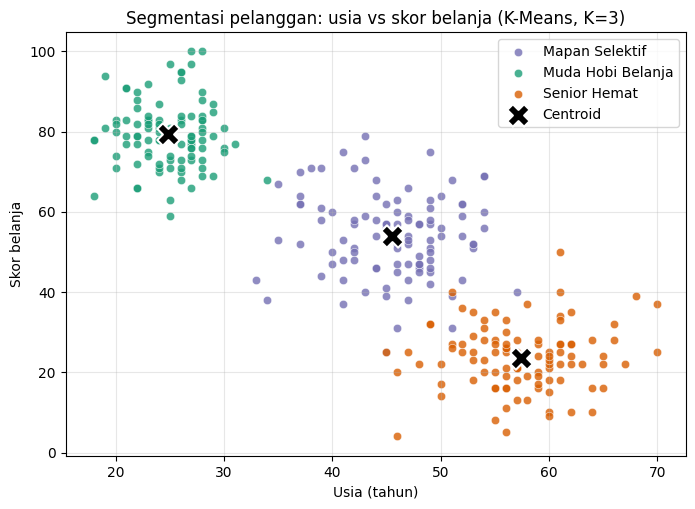

In [16]:
plt.figure(figsize=(8,5.5))
warna = {'Muda Hobi Belanja':'#1b9e77', 'Mapan Selektif':'#7570b3', 'Senior Hemat':'#d95f02'}
for s, g in df.groupby('segmen'):
    plt.scatter(g['usia'], g['skor_belanja'], s=36, alpha=.8, color=warna[s], edgecolor='white', linewidth=.4, label=s)

# centroid dikembalikan ke skala asli
sc = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']])
cent = sc.inverse_transform(kmeans.cluster_centers_)
plt.scatter(cent[:,0], cent[:,2], marker='X', s=260, c='black', edgecolor='white', linewidth=1.5, label='Centroid', zorder=5)

plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja'); plt.title('Segmentasi pelanggan: usia vs skor belanja (K-Means, K=3)')
plt.legend(); plt.grid(alpha=.3); plt.show()

Pada bidang usia vs skor belanja, ketiga segmen terlihat terpisah rapi: pelanggan **muda** di kiri-atas (belanja tinggi), **paruh baya** di tengah (belanja sedang), dan **senior** di kanan-bawah (belanja rendah). Tanda ✕ hitam adalah centroid tiap cluster.

---
## E. Refleksi

**9. Bagaimana K-Means menemukan kelompok tanpa label?**  
K-Means tidak membutuhkan jawaban benar; ia hanya memakai **kemiripan (jarak)** antar-titik. Ia menaruh K centroid awal secara acak, lalu mengulang dua langkah: (1) *assignment* — tiap titik masuk ke centroid terdekat; (2) *update* — centroid dihitung ulang sebagai rata-rata anggotanya. Proses diulang sampai centroid tidak berpindah lagi (konvergen). Pada akhirnya algoritma menemukan pembagian yang meminimalkan total jarak kuadrat titik ke centroid-nya (inertia). Kelompok muncul dari struktur data itu sendiri; manusialah yang kemudian memberi nama dan makna pada tiap kelompok.

**10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**  
Karena data dibangun dari **tiga kelompok alami** yang terpisah jelas. Dari K=1 ke K=3, setiap cluster tambahan memisahkan satu kelompok alami sehingga inertia anjlok (900 → 432 → 97). Setelah K=3 setiap kelompok sudah rapat, sehingga cluster tambahan hanya memecah kelompok yang sebenarnya satu dan memberi perbaikan kecil (13 poin atau kurang per langkah). Perubahan dari curam ke landai itulah siku di K=3. Hasil ini didukung silhouette: K=3 (0,72) lebih baik daripada K=5 (0,58).

**11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**  
K-Means berbasis jarak, jadi fitur dengan rentang nilai besar mendominasi jarak. Dengan pendapatan berskala jutaan, usia dan skor belanja hampir tidak diperhitungkan. Dampaknya (Latihan 7): cluster hampir hanya mengikuti pendapatan, dua segmen berbeda (muda-boros dan senior-hemat) tergabung karena pendapatannya mirip, dan skor silhouette bisa terlihat bagus padahal segmentasinya tidak bermakna. `StandardScaler` menyamakan skala sehingga tiap fitur berkontribusi adil.

---
## Kesimpulan Akhir
- Data pelanggan dipersiapkan dan di-*scaling* dengan `StandardScaler` sebelum clustering.
- Metode Elbow menunjukkan **K = 3** sebagai jumlah cluster optimal.
- K-Means (K=3) menghasilkan **tiga segmen seimbang (100/100/100)** dengan **silhouette = 0,72** (pemisahan sangat baik).
- Segmen yang ditemukan: **Muda Hobi Belanja**, **Mapan Selektif**, dan **Senior Hemat**, masing-masing dengan strategi pemasaran yang berbeda.
- K=5 memberi silhouette lebih rendah (0,58); tanpa scaling, segmen tercampur dan hasilnya menyesatkan. Maka K=3 dengan scaling adalah konfigurasi terbaik.